# CV development tICA

## imports

In [1]:
import os
import glob
import numpy as np
import mdtraj as md
import seaborn as sns
import matplotlib.pyplot as plt
import copy
import matplotlib as mpl

from scipy.signal import savgol_filter

from deeptime.decomposition import TICA
from deeptime.covariance import KoopmanWeightingEstimator

from mpl_toolkits.mplot3d import Axes3D
from matplotlib.animation import FuncAnimation, PillowWriter
from mlcolvar.utils.io import load_dataframe


In [2]:
#plot-related stuff
import matplotlib.pyplot as plt
from IPython.display import clear_output

#set bigger font sizes
SMALL_SIZE = 8
MEDIUM_SIZE = 8
BIG_SIZE = 8
plt.rc('font', size=SMALL_SIZE)        # controls default text sizes
plt.rc('axes', titlesize=SMALL_SIZE)   # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)  # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)  # legend fontsize
plt.rc('figure', titlesize=BIG_SIZE)   # fontsize of the figure title

try:
# https://github.com/luigibonati/fessa-color-palette/blob/master/fessa.py
    import fessa
    plt.set_cmap('fessa')
except:
    pass # no big deal

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 8,

    # Axes
    "axes.titlesize": 8,
    "axes.labelsize": 8,

    # Tick labels
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,

    # Legend
    "legend.fontsize": 8,

    # Figure title
    "figure.titlesize": 8,

    # Colorbar (uses axes settings, but these help in some cases)
    "axes.titlepad": 6,
})

In [3]:
#useful constants for our simulations
KB = 0.0083144621
T = 300
BETA = 1/(KB*T)
KBT = KB*T

cm2inch = 1/2.54

## Interchain CV

In [4]:
def residue_com(traj, residue):
    """
    Compute center of mass of residue using only heavy atoms.
    Returns: array (n_frames, 3)
    """
    # select non-hydrogen atoms
    heavy_atoms = [a for a in residue.atoms if a.element.symbol != "H"]

    atom_indices = [a.index for a in heavy_atoms]
    masses = np.array([a.element.mass for a in heavy_atoms], float)

    coords = traj.xyz[:, atom_indices, :]  # shape (n_frames, n_atoms, 3)

    com = np.sum(coords * masses[None, :, None], axis=1) / masses.sum()
    return com


def build_residue_index_pairs(residues1, residues2):
    """
    Build a list of (res1.resSeq, res2.resSeq) in the same order
    contacts are flattened into the feature vector.
    """
    pairs = []
    for r1 in residues1:
        for r2 in residues2:
            pairs.append((r1.resSeq, r2.resSeq))
    return pairs


def com_contacts(traj, residues1, residues2, cutoff=None):
    """
    Compute residue-COM to residue-COM distances for every frame.
    Also returns residue index mapping.
    """
    n_frames = traj.n_frames
    n1 = len(residues1)
    n2 = len(residues2)

    com1 = np.zeros((n1, n_frames, 3))
    com2 = np.zeros((n2, n_frames, 3))

    # Compute COMs
    for i, r in enumerate(residues1):
        com1[i] = residue_com(traj, r)

    for j, r in enumerate(residues2):
        com2[j] = residue_com(traj, r)

    # Build residue index mapping
    residue_pairs = build_residue_index_pairs(residues1, residues2)

    # Compute features frame-by-frame
    features = []
    for frame in range(n_frames):
        d = np.linalg.norm(
            com1[:, frame][:, None, :] - com2[:, frame][None, :, :],
            axis=2
        )

        if cutoff:
            x = d / cutoff
            d = (1 - x**6) / (1 - x**8)
        else:
            None

        features.append(d.flatten())

    return np.array(features), residue_pairs


def process_trajectory(top, xtc, sel1="chainid 0", sel2="chainid 1", cutoff=None):
    """
    Return:
        features  = (n_frames, n_contacts)
        times     = (n_frames,)
        residue_pairs = global contact mapping
    """
    traj = md.load(xtc, top=top, stride=10)
    topology = traj.topology

    # MDTraj stores time in picoseconds
    times = traj.time.copy()  # shape (n_frames,)

    # Select residues
    res1 = [r for r in topology.residues if r.chain.index == int(sel1.split()[-1])]
    res2 = [r for r in topology.residues if r.chain.index == int(sel2.split()[-1])]

    print(f"- {xtc} | frames: {traj.n_frames}, res1={len(res1)}, res2={len(res2)}")

    features, residue_pairs = com_contacts(traj, res1, res2, cutoff)
    return features, times, residue_pairs


def process_multiple_trajectories(xtcs, top, sel1="chainid 0", sel2="chainid 1", cutoff=None):
    """
    Return:
        list_of_features  → [array(n_frames_i, n_contacts), ...]
        list_of_times     → [array(n_frames_i,), ...]
        residue_pairs     → mapping of feature index to (res1,res2)
    """
    print(f"Found {len(xtcs)} trajectories.")

    feature_list = []
    time_list = []
    residue_pairs = None

    for xtc in xtcs:
        feats, times, pairs = process_trajectory(top, xtc, sel1, sel2, cutoff)
        feature_list.append(feats)
        time_list.append(times)

        if residue_pairs is None:
            residue_pairs = pairs

    return feature_list, time_list, residue_pairs


In [5]:
traj_paths = [r'C:/Users/vacaa/Documents/REPORTS/170/data/Binding/20_nobias/1/1onv_pbc.xtc',
         r'C:/Users/vacaa/Documents/REPORTS/170/data/Binding/20_nobias_350K/1/1onv_pbc.xtc'
         ]
top_path = r'C:/Users/vacaa/Documents/REPORTS/170/data/Binding/20_nobias/1/1onv_pbc_prot.pdb'

# Two chains (MDTraj numbers chains starting from 0)
sel1 = "chainid 0"
sel2 = "chainid 1"

features, times, residue_pairs = process_multiple_trajectories(
    xtcs=traj_paths,
    top=top_path,
    sel1=sel1,
    sel2=sel2,
    cutoff=0.7
)
residue_pairs_arr = np.array(residue_pairs)
print(len(features), "trajectories")
print("Traj 0 features shape:", features[0].shape)
print("Traj 0 times shape:", times[0].shape)
print("Total contact pairs:", len(residue_pairs))

Found 2 trajectories.
- C:/Users/vacaa/Documents/REPORTS/170/data/Binding/20_nobias/1/1onv_pbc.xtc | frames: 20111, res1=67, res2=21
- C:/Users/vacaa/Documents/REPORTS/170/data/Binding/20_nobias_350K/1/1onv_pbc.xtc | frames: 20683, res1=67, res2=21
2 trajectories
Traj 0 features shape: (20111, 1407)
Traj 0 times shape: (20111,)
Total contact pairs: 1407


In [9]:
# from sklearn.decomposition import tICA

# 1. Concatenate feature matrices from all trajectories
features_con = np.concatenate(features, axis=0)   # shape: (total_frames, n_contacts)
time_con = np.concatenate(times,) 
# 2. Compute per-feature standard deviation
stds = np.var(features_con, axis=0)

# 3. Build mask for feature selection
mask = stds > 0.025
mask = (features_con[0] > 0.75)

# 4. Filter features (transpose not needed)
features_contacts_con = features_con[:, mask]    # shape: (total_frames, n_selected_features)
features_contacts = [f[:, mask] for f in features]

# 5. Filter residue pairs with same mask
residue_pairs_interchain = np.array(residue_pairs)[mask]

# print("Filtered features shape:", features1.shape)
print("Filtered residue pairs:", residue_pairs_interchain)

# 6. tICA computation
lag = 1
tica = TICA(lagtime=lag, dim = 3)

#reweightning
koopman_estimator = KoopmanWeightingEstimator(lagtime=lag)
reweighting_model = koopman_estimator.fit(features_contacts,lagtime=lag).fetch_model()

tica_model_reweighted = tica.fit(features_contacts, weights=reweighting_model,lagtime=lag).fetch_model()

# tica_model_reweighted = tica.fit_from_timeseries(np.concatenate(features_contacts, axis = 0), weights=weights_list_eq).fetch_model()


cv2_tica = tica_model_reweighted.transform(features_contacts_con)
cv2_tica_list = [tica_model_reweighted.transform(f) for f in features_contacts]

print("tICA transformed shape:", cv2_tica.shape)
# print("Explained variance ratio:", cv2_tica.explained_variance_ratio_)

# Eigenvectors (principal component loadings)
sc1 = tica_model_reweighted.singular_vectors_left[0]   # shape: (n_selected_features,)
print("SC1 shape:", sc1.shape)

components_interchain = tica_model_reweighted.instantaneous_coefficients.T[:3]

Filtered residue pairs: [[470 950]
 [470 953]
 [470 954]
 [471 947]
 [471 950]
 [474 949]
 [474 950]
 [478 949]
 [486 949]
 [490 949]
 [490 952]
 [490 953]
 [493 953]
 [494 953]
 [494 956]
 [497 957]
 [498 956]
 [498 957]
 [498 959]
 [498 960]
 [501 960]
 [502 957]
 [502 960]
 [504 961]]
tICA transformed shape: (40794, 3)
SC1 shape: (24,)


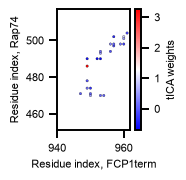

In [164]:
component_index = 0

plt.figure(figsize=(3*cm2inch, 4*cm2inch))
residue_pairs_intrachin_arr = np.array(residue_pairs_interchain)
# sc = plt.scatter(
#     residue_pairs_interchain[:, 0],
#     residue_pairs_interchain[:, 1],
#     c=components_interchain[0]-components_interchain[1],
#     cmap="bwr",
#     alpha = 0.7,
#     s=10,
#     edgecolor="k"
# )

sc = plt.scatter(
    residue_pairs_interchain[:, 1],
    residue_pairs_interchain[:, 0],
    c=components_interchain[component_index],
    cmap="bwr",
    alpha = 1.0,
    s=3,
    linewidths = 0.2,
    edgecolor="k"
)

plt.colorbar(sc, label="tICA weights")
plt.xlabel("Residue index, FCP1term")
plt.ylabel("Residue index, Rap74")
plt.xlim(940,962)
plt.ylim(451,517)
# plt.tight_layout()

plt.savefig(
    f"images/interchain_tICA{component_index+1}.png",
    dpi=600,
    bbox_inches="tight",
)
plt.show()


NameError: name 'legend' is not defined

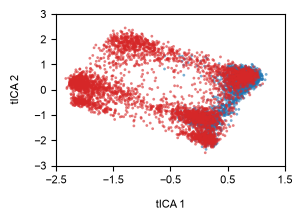

In [10]:
# -----------------------------
# Figure
# -----------------------------
fig, ax = plt.subplots(figsize=(7.5*cm2inch, 5*cm2inch))

colors = ["#1f77b4", "#d62728"]  # colorblind-safe
stride = 5

for temp, tica_cv, color in zip([300, 350], cv2_tica_list, colors):

    ax.scatter(
        tica_cv[::stride, 0],
        tica_cv[::stride, 1],
        s=4,
        alpha=0.6,
        color=color,
        edgecolors="none",
        label=f"{temp} K"
    )

# -----------------------------
# Axes labels
# -----------------------------
ax.set_xlabel("tICA 1", labelpad=10)
ax.set_ylabel("tICA 2", labelpad=10)
ax.tick_params(direction="out")

# -----------------------------
# Legend (boxed, clean)
# -----------------------------
# legend = ax.legend(
#     loc="upper left",
#     frameon=False,
#     ncols = 2,
# )

ax.set_xlim(-2.5,1.5)
ax.set_ylim(-3.0,3.0)
ax.set_xticks(np.arange(-2.5,1.51, 1.0))
ax.set_yticks(np.arange(-3.0,3.01, 1.0))

legend.get_frame().set_linewidth(1.0)

# -----------------------------
# Final layout
# -----------------------------
plt.tight_layout()
# plt.savefig(
#     f"images/Rap74-FCP1term_states.png",
#     dpi=600
# )
plt.show()


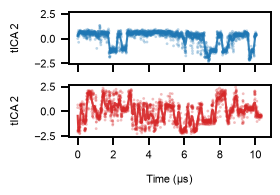

In [165]:
# -----------------------------
# Figure
# -----------------------------
fig, axs = plt.subplots(
    2, 1,
    figsize=(7*cm2inch, 5*cm2inch),
    sharex=True,
    sharey=True
)
component_index = 1
colors = ["#1f77b4", "#d62728"]  # colorblind-safe
stride = 10

# SavGol parameters (tuned for MD trajectories)
window_length = 51   # must be odd; increase for stronger smoothing
polyorder = 3

for temp, tica_cv, ax, color in zip([300, 350], cv2_tica_list, axs, colors):

    time = np.arange(0, tica_cv.shape[0], stride) / 2000
    y = tica_cv[::stride, component_index]

    # Scatter (raw data)
    ax.scatter(
        time,
        y,
        s=4,
        alpha=0.3,
        color=color,
        edgecolors="none",
        label=f"{temp} K"
    )

    # Savitzky–Golay smoothing
    if len(y) >= window_length:
        y_smooth = savgol_filter(y, window_length, polyorder)
        ax.plot(
            time,
            y_smooth,
            color=color,
            lw=1.5,
            alpha=0.9,
            # label="Smoothed"
        )
        
    ax.tick_params(direction="out")

# -----------------------------
# Axis labels
# -----------------------------
axs[-1].set_xlabel("Time (μs)", labelpad=10)
axs[0].set_ylabel(f"tICA {component_index+1}", labelpad=10)
axs[1].set_ylabel(f"tICA {component_index+1}", labelpad=10)

# -----------------------------
# Final layout
# -----------------------------
plt.tight_layout()
plt.savefig(
    f"images/tICA1_Rap74-FCP1term_dynamics_tICA{component_index+1}.png",
    dpi=600
)
plt.show()


## Hydrogen bonds

In [740]:
import re

def parse_plumed_contactmap(line):
    """
    Parse a PLUMED CONTACTMAP line:
    Example:
    cmap_hel: CONTACTMAP ATOMS1=1207,1170 ATOMS2=1218,1177 ... SWITCH={...}

    Returns:
        atom_pairs = [(1207,1170), (1218,1177), ...]
    """
    pattern = r"ATOMS\d+=([\d]+),([\d]+)"
    matches = re.findall(pattern, line)

    atom_pairs = [(int(a1), int(a2)) for a1, a2 in matches]
    return atom_pairs


In [741]:
def contact_features_atom_pairs(traj, atom_pairs, switching=True, d0=0.3):
    """
    Compute distances or switching function for given atom pairs.

    Parameters
    ----------
    traj : mdtraj.Trajectory
    atom_pairs : list of (i,j)
    switching : bool
        If True, apply (1-x^6)/(1-x^8) switching function
    d0 : float
        Switching function R_0 (nm)

    Returns
    -------
    features : array (n_frames, n_pairs)
    """
    pairs_np = np.array(atom_pairs, dtype=int)

    # Compute raw distances
    dist = md.compute_distances(traj, pairs_np)  # nm

    if switching:
        x = dist / d0
        return (1 - x**6) / (1 - x**8)

    return dist


In [742]:
def process_trajectory(top, xtc, mode="com", atom_pairs=None, cutoff=0.3):
    """
    Added new mode: mode="atom_pair_contacts"
    Requires: atom_pairs=[(i,j), ...]
    """

    traj = md.load(xtc, top=top,stride = 10)
    topology = traj.topology
    times = traj.time.copy()

    if mode == "com":
        raise NotImplementedError("Use your existing COM code here.")

    elif mode == "alpha_hbond":
        raise NotImplementedError("Your previous helix code goes here.")

    elif mode == "atom_pair_contacts":
        if atom_pairs is None:
            raise ValueError("atom_pairs must be provided for this mode")

        features = contact_features_atom_pairs(
            traj, atom_pairs, switching=True, d0=cutoff
        )
        residue_pairs = None  # Not used here

    else:
        raise ValueError(f"Unknown mode: {mode}")

    print(f"- {xtc}: frames={traj.n_frames}, features={features.shape[1]}")

    return features, times, residue_pairs


def process_multiple_trajectories(base_dir, top, mode="com",
                                  atom_pairs=None, cutoff=0.3):

    xtcs = get_all_xtc_paths(base_dir)
    print(f"Found {len(xtcs)} trajectories.")

    feature_list = []
    time_list = []

    for xtc in xtcs:
        feats, times, _ = process_trajectory(
            top=top,
            xtc=xtc,
            mode=mode,
            atom_pairs=atom_pairs,
            cutoff=cutoff
        )

        feature_list.append(feats)
        time_list.append(times)

    return feature_list, time_list


In [743]:
plumed_line = "cmap_hel: CONTACTMAP ATOMS11=1177,1215 ATOMS1=1188,1227 ATOMS2=1203,1242 ATOMS3=1213,1259 ATOMS4=1225,1269 ATOMS5=1240,1291 ATOMS6=1257,1301 ATOMS7=1267,1320 ATOMS8=1289,1335 ATOMS9=1299,1345 ATOMS10=1318,1360 ATOMS12=1333,1379 ATOMS13=1343,1393 ATOMS14=1358,1405 SWITCH={RATIONAL R_0=0.3 NN=6 MM=8}"

atom_pairs = np.array(parse_plumed_contactmap(plumed_line)) - 1

features_hel, times = process_multiple_trajectories(
    base_dir=base_dir,
    top=top,
    mode="atom_pair_contacts",
    atom_pairs=atom_pairs,
    cutoff=0.3
)


Found 2 trajectories.
- /home/msbb/Vasily/REPORTS/170/OPES_MD/nobias/300k.xtc: frames=20111, features=14
- /home/msbb/Vasily/REPORTS/170/OPES_MD/nobias/350k.xtc: frames=20683, features=14


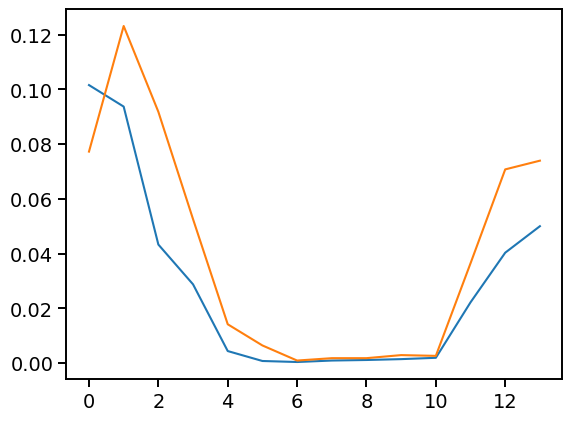

In [744]:
plt.plot(np.var(features_hel[0], axis = 0))
plt.plot(np.var(features_hel[1], axis = 0))


In [745]:
#correlational analysis instead of tICA

In [768]:
# 1. Build mask for feature selection
# mask = C_lag[0].diagonal() >-1      # or your threshold

# 2. Filter features (transpose not needed)
features3 = [ft[:] for ft in features_hel]    # shape: (total_frames, n_selected_features)
features3_con = np.concatenate(features3, axis = 0)

# 3. tICA computation
# tICA = TICA(dim=1, )
# cv5_tICA = tICA.fit_transform(features3_con, lag = 10)
# cv5_tICA_list = [tICA.transform(ft) for ft in features3]


# print("tICA transformed shape:", cv6_tICA.shape)
# print("Explained variance ratio:", tICA.explained_variance_ratio_)

# 6. tICA computation
tica = TICA(lagtime=5, dim = 3)

#reweightning
koopman_estimator = KoopmanWeightingEstimator(lagtime=50)
reweighting_model = koopman_estimator.fit(features3).fetch_model()

tica_model_reweighted = tica.fit(features3, weights=reweighting_model).fetch_model()

cv6_tica = tica_model_reweighted.transform(features3_con)
cv6_tica_list = [tica_model_reweighted.transform(f) for f in features_hel]


# Eigenvectors (principal component loadings)
components_helix = tica_model_reweighted.instantaneous_coefficients.T[:1]


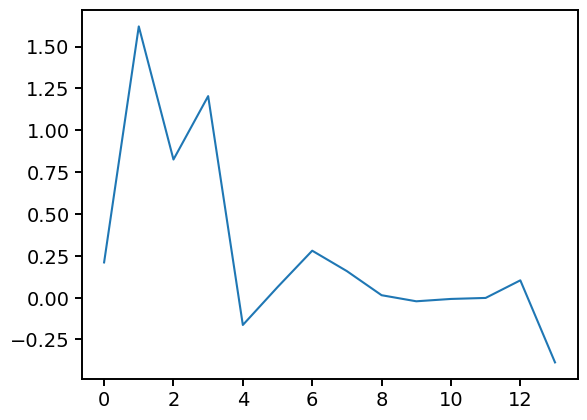

In [769]:
plt.plot(components_helix.T)

In [770]:
cmap_str = f'COEFFICIENTS='
for i, comp in enumerate(components_helix[0]):
    cmap_str += f'{comp},'
print(cmap_str)

COEFFICIENTS=0.21023900106404758,1.620418222794676,0.8250679789620439,1.2038729122671514,-0.16345327400029053,0.06270693624738578,0.2803787045462275,0.15826335654435364,0.014385417020524547,-0.02192196888189759,-0.007890624450950177,-0.00188911728132211,0.10329406651562506,-0.38700066459459587,


[(array([0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 3.000e+00,
         1.410e+02, 6.300e+02, 1.470e+03, 1.642e+03, 1.447e+03, 1.526e+03,
         1.414e+03, 1.162e+03, 1.014e+03, 9.250e+02, 8.530e+02, 8.060e+02,
         8.390e+02, 9.830e+02, 1.202e+03, 1.551e+03, 1.750e+03, 1.874e+03,
         1.900e+03, 1.669e+03, 1.486e+03, 1.095e+03, 8.190e+02, 5.690e+02,
         3.760e+02, 2.760e+02, 1.970e+02, 1.520e+02, 1.640e+02, 1.110e+02,
         1.170e+02, 1.360e+02, 1.060e+02, 1.020e+02, 8.900e+01, 9.600e+01,
         9.500e+01, 9.300e+01, 7.800e+01, 7.100e+01, 8.400e+01, 6.600e+01,
         6.300e+01, 7.200e+01, 6.200e+01, 5.300e+01, 5.900e+01, 6.100e+01,
         5.700e+01, 5.000e+01, 4.000e+01, 5.300e+01, 3.800e+01, 5.800e+01,
         3.900e+01, 4.200e+01, 4.000e+01, 3.600e+01, 3.400e+01, 3.500e+01,
         4.000e+01, 3.600e+01, 3.700e+01, 2.700e+01, 4.300e+01, 5.100e+01,
         4.800e+01, 4.200e+01, 5.100e+01, 4.000e+01, 5.100e+01, 5.300e+01,
         6.400e+01, 7.500

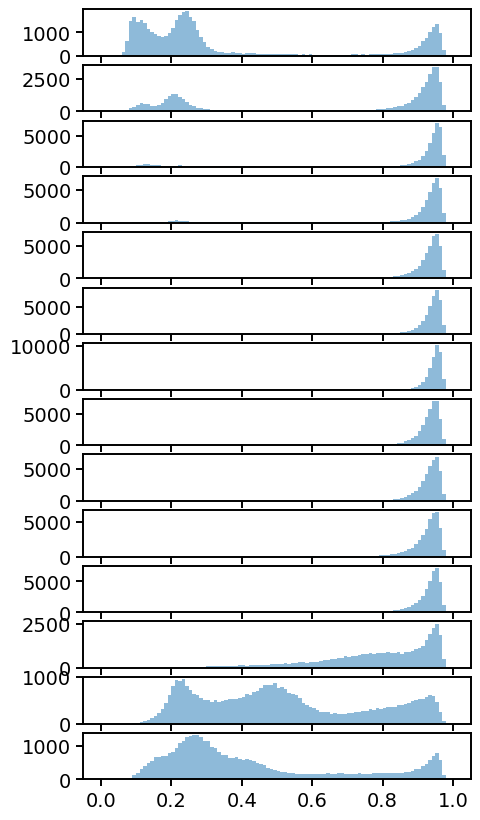

In [771]:
fig, axs = plt.subplots(features3_con.shape[1], 1,figsize = (5,10))
[ax.hist(features3_con[:,i], bins = 100, range = (0,1), alpha = 0.5) for i,ax in enumerate(axs)]

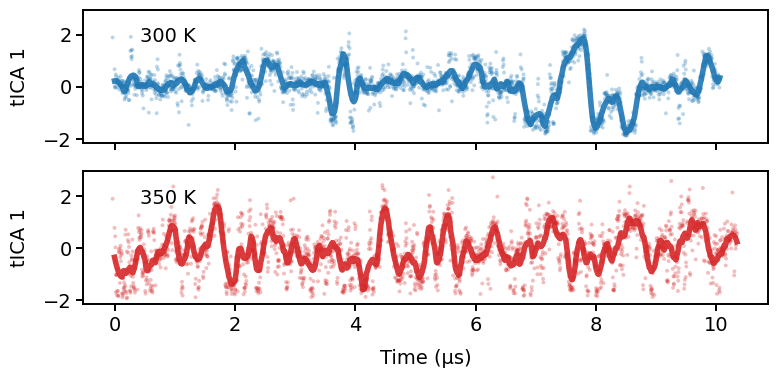

In [772]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

# -----------------------------
# Global style (publication)
# -----------------------------
plt.rcParams.update({
    "font.size": 14,
    "font.family": "sans-serif",
    "axes.linewidth": 1.4,
    "xtick.major.size": 5,
    "ytick.major.size": 5,
    "xtick.major.width": 1.4,
    "ytick.major.width": 1.4,
})

# -----------------------------
# Figure
# -----------------------------
fig, axs = plt.subplots(
    2, 1,
    figsize=(8, 4.0),
    sharex=True,
    sharey=True
)

colors = ["#1f77b4", "#d62728"]  # colorblind-safe
stride = 10

# SavGol parameters (tuned for MD trajectories)
window_length = 51   # must be odd; increase for stronger smoothing
polyorder = 3

for temp, tica_cv, ax, color in zip([300, 350], cv6_tica_list, axs, colors):

    time = np.arange(0, tica_cv.shape[0], stride) / 2000
    y = tica_cv[::stride, 1]

    # Scatter (raw data)
    ax.scatter(
        time,
        y,
        s=8,
        alpha=0.3,
        color=color,
        edgecolors="none",
        label=f"{temp} K"
    )

    # Savitzky–Golay smoothing
    if len(y) >= window_length:
        y_smooth = savgol_filter(y, window_length, polyorder)
        ax.plot(
            time,
            y_smooth,
            color=color,
            lw=4.0,
            alpha=0.9,
            # label="Smoothed"
        )

    ax.legend(
        loc="upper left",
        frameon=False,
        handlelength=1.2
    )

    ax.tick_params(direction="out")

# -----------------------------
# Axis labels
# -----------------------------
axs[-1].set_xlabel("Time (μs)", labelpad=10)
axs[0].set_ylabel("tICA 1", labelpad=10)
axs[1].set_ylabel("tICA 1", labelpad=10)

# -----------------------------
# Final layout
# -----------------------------
plt.tight_layout()
# plt.savefig(
#     "/home/msbb/Vasily/REPORTS/170/OPES_MD/images/paper/tICA_dynamics.png",
#     dpi=600
# )
plt.show()


In [912]:
np.sum(features3[::stride], axis = 0)

array([[0.32090834, 0.9525135 , 0.91279536, ..., 0.93421704, 0.6527382 ,
        0.4911211 ],
       [0.24344254, 0.93684876, 0.9517927 , ..., 0.7845468 , 0.35022804,
        0.2837427 ],
       [0.93980414, 0.8896993 , 0.93296677, ..., 0.86810994, 0.46436188,
        0.3385673 ],
       ...,
       [0.94183064, 0.9096582 , 0.96540034, ..., 0.75398225, 0.36296943,
        0.30720037],
       [0.9145472 , 0.94820213, 0.913025  , ..., 0.8004019 , 0.5967654 ,
        0.27569708],
       [0.87357026, 0.98002994, 0.9500023 , ..., 0.68046004, 0.404396  ,
        0.34320325]], shape=(20111, 14), dtype=float32)

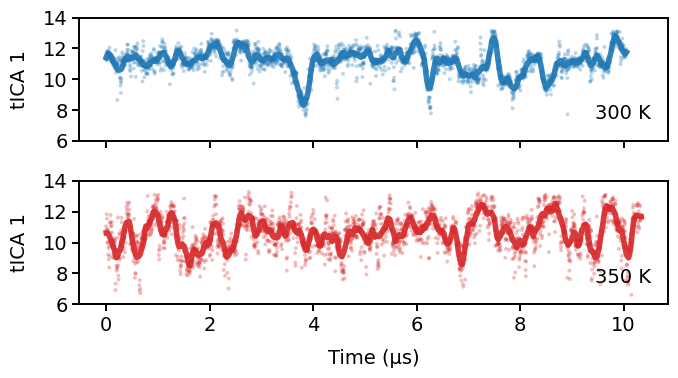

In [924]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

# -----------------------------
# Global style (publication)
# -----------------------------
plt.rcParams.update({
    "font.size": 14,
    "font.family": "sans-serif",
    "axes.linewidth": 1.4,
    "xtick.major.size": 5,
    "ytick.major.size": 5,
    "xtick.major.width": 1.4,
    "ytick.major.width": 1.4,
})

# -----------------------------
# Figure
# -----------------------------
fig, axs = plt.subplots(
    2, 1,
    figsize=(7, 4.0),
    sharex=True,
    sharey=True
)

colors = ["#1f77b4", "#d62728"]  # colorblind-safe
stride = 10

# SavGol parameters (tuned for MD trajectories)
window_length = 51   # must be odd; increase for stronger smoothing
polyorder = 3

for temp, tica_cv, ax, color in zip([300, 350], features3, axs, colors):

    time = np.arange(0, tica_cv.shape[0], stride) / 2000
    
    y = np.sum(tica_cv[::stride], axis = 1)

    # Scatter (raw data)
    ax.scatter(
        time,
        y,
        s=8,
        alpha=0.3,
        color=color,
        edgecolors="none",
        label=f"{temp} K"
    )

    # Savitzky–Golay smoothing
    if len(y) >= window_length:
        y_smooth = savgol_filter(y, window_length, polyorder)
        ax.plot(
            time,
            y_smooth,
            color=color,
            lw=4.0,
            alpha=0.9,
            # label="Smoothed"
        )

    ax.legend(
        loc="lower right",
        frameon=False,
        handlelength=1.2
    )

    ax.tick_params(direction="out")
    ax.set_ylim(6,14)
    ax.set_yticks([6,8,10,12,14])

# -----------------------------
# Axis labels
# -----------------------------
axs[-1].set_xlabel("Time (μs)", labelpad=10)
axs[0].set_ylabel("tICA 1", labelpad=10)
axs[1].set_ylabel("tICA 1", labelpad=10)

# -----------------------------
# Final layout
# -----------------------------
plt.tight_layout()
plt.savefig(
    "/home/msbb/Vasily/REPORTS/170/OPES_MD/images/paper/helix_dynamics.png",
    dpi=600
)
plt.show()


## Intrachain contacts of Rap74

In [166]:
def get_all_xtc_paths(base_dir):
    xtc_files = []
    for root, _, files in os.walk(base_dir):
        for f in files:
            if f.endswith(".xtc"):
                xtc_files.append(os.path.join(root, f))
    return sorted(xtc_files)


def residue_com(traj, residue):
    """
    Center of mass of residue using heavy atoms only.
    Returns (n_frames, 3)
    """
    heavy_atoms = [a for a in residue.atoms if a.element.symbol != "H"]

    atom_idx = np.array([a.index for a in heavy_atoms], dtype=int)
    masses = np.array([a.element.mass for a in heavy_atoms], dtype=float)

    xyz = traj.xyz[:, atom_idx, :]
    return np.sum(xyz * masses[None, :, None], axis=1) / masses.sum()


def select_residues(topology, selection):
    """
    Select residues from an MDTraj atom selection.
    """
    atom_indices = topology.select(selection)
    residues = sorted(
        {topology.atom(i).residue for i in atom_indices},
        key=lambda r: (r.chain.index, r.resSeq)
    )
    return residues


def build_residue_pairs(res1, res2, intrachain):
    """
    Build residue pair list with correct ordering and no duplicates.
    """
    pairs = []

    if intrachain:
        for i in range(len(res1)):
            for j in range(i + 1, len(res1)):
                pairs.append((res1[i], res1[j]))
    else:
        for r1 in res1:
            for r2 in res2:
                pairs.append((r1, r2))

    return pairs


def com_contacts(traj, residues1, residues2, intrachain=False, cutoff=None):
    """
    Compute COM–COM distances for intra- or interchain contacts.

    Returns:
        features        (n_frames, n_contacts)
        residue_pairs   [((chain,resSeq),(chain,resSeq)), ...]
    """
    n_frames = traj.n_frames

    # Precompute COMs
    com = {}
    for r in set(residues1) | set(residues2):
        com[r] = residue_com(traj, r)

    residue_pairs = build_residue_pairs(residues1, residues2, intrachain)
    n_contacts = len(residue_pairs)

    features = np.zeros((n_frames, n_contacts), dtype=float)

    for k, (r1, r2) in enumerate(residue_pairs):
        d = np.linalg.norm(com[r1] - com[r2], axis=1)

        if cutoff is not None:
            x = d / cutoff
            d = (1 - x**6) / (1 - x**8)

        features[:, k] = d

    residue_pairs = [
        ((r1.chain.index, r1.resSeq),
         (r2.chain.index, r2.resSeq))
        for r1, r2 in residue_pairs
    ]

    return features, residue_pairs


def process_trajectory(top, xtc,
                        sel1,
                        sel2=None,
                        cutoff=None):
    """
    sel1 == sel2 or sel2=None → intrachain
    sel1 != sel2             → interchain
    """
    traj = md.load(xtc, top=top, stride=10)
    topology = traj.topology
    times = traj.time.copy()

    res1 = select_residues(topology, sel1)

    if sel2 is None or sel2 == sel1:
        intrachain = True
        res2 = res1
    else:
        intrachain = False
        res2 = select_residues(topology, sel2)

    features, residue_pairs = com_contacts(
        traj, res1, res2, intrachain=intrachain, cutoff=cutoff
    )

    print(
        f"- {xtc} | frames={traj.n_frames}, "
        f"contacts={features.shape[1]}, "
        f"{'intra' if intrachain else 'inter'}-chain"
    )

    return features, times, residue_pairs


def process_multiple_trajectories(xtcs, top,
                                  sel1,
                                  sel2=None,
                                  cutoff=None):
    
    print(f"Found {len(xtcs)} trajectories.")

    feature_list = []
    time_list = []
    residue_pairs = None

    for xtc in xtcs:
        feats, times, pairs = process_trajectory(
            top, xtc, sel1, sel2, cutoff
        )

        feature_list.append(feats)
        time_list.append(times)

        if residue_pairs is None:
            residue_pairs = pairs

    return feature_list, time_list, residue_pairs


In [167]:
traj_paths = [r'C:/Users/vacaa/Documents/REPORTS/170/data/Binding/20_nobias/1/1onv_pbc.xtc',
         r'C:/Users/vacaa/Documents/REPORTS/170/data/Binding/20_nobias_350K/1/1onv_pbc.xtc'
         ]
top_path = r'C:/Users/vacaa/Documents/REPORTS/170/data/Binding/20_nobias/1/1onv_pbc_prot.pdb'

# Two chains (MDTraj numbers chains starting from 0)
sel1 = "chainid 0"
sel2 = "chainid 0"


features, times, residue_pairs = process_multiple_trajectories(
    xtcs=traj_paths,
    top=top_path,
    sel1=sel1,
    sel2=sel2,
    cutoff=0.7
)
residue_pairs = [(int(rp[0][1]),int(rp[1][1])) for rp in residue_pairs]

residue_pairs_arr = np.array(residue_pairs)
print(len(features), "trajectories")
print("Traj 0 features shape:", features[0].shape)
print("Traj 0 times shape:", times[0].shape)
print("Total contact pairs:", len(residue_pairs))

Found 2 trajectories.
- C:/Users/vacaa/Documents/REPORTS/170/data/Binding/20_nobias/1/1onv_pbc.xtc | frames=20111, contacts=2211, intra-chain
- C:/Users/vacaa/Documents/REPORTS/170/data/Binding/20_nobias_350K/1/1onv_pbc.xtc | frames=20683, contacts=2211, intra-chain
2 trajectories
Traj 0 features shape: (20111, 2211)
Traj 0 times shape: (20111,)
Total contact pairs: 2211


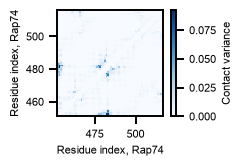

In [113]:
from matplotlib.colors import LogNorm
from scipy import ndimage

# -----------------------------
# Data preparation
# -----------------------------
resA = np.sort(np.unique(residue_pairs_arr[:, 0]))
resB = np.sort(np.unique(residue_pairs_arr[:, 1]))
minA,minB = np.min(resA), np.min(resB)
n_res_protA = len(resA)+2
n_res_protB = len(resB)+2


var_matrix = np.zeros((n_res_protA,n_res_protB))
variance = np.var(features[0], axis=0)
k = 0
for i in range(len(resA)):
    for j in range(i+2, len(resB)+2):
        var_matrix[i,j] = variance[k]
        k += 1

var_matrix += var_matrix.T

# -----------------------------
# Plot
# -----------------------------
fig, ax = plt.subplots(figsize=(4*cm2inch, 3.5*cm2inch))
rotated_img = ndimage.rotate(var_matrix, 90)
im = ax.imshow(
    rotated_img,
    cmap="Blues",
    origin="upper",
    aspect="equal",
    interpolation="nearest",
    # norm=LogNorm(),  # remove if zeros present
    extent=[
        resB.min(), resB.max(),
        resA.min(), resA.max()
    ]
)

# -----------------------------
# Axes labels & ticks
# -----------------------------
ax.set_xlabel("Residue index, Rap74", )
ax.set_ylabel("Residue index, Rap74", )

ax.tick_params(direction="out")


# Rotate x-axis tick labels
plt.setp(ax.get_xticklabels(), rotation=0, ha="center", va="top")

# -----------------------------
# Colorbar
# -----------------------------
cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.05,
    pad=0.06
)
cbar.set_label("Contact variance", )

# -----------------------------
# Title
# -----------------------------
plt.savefig(
    "images/Variance_map_300K.png",
    dpi=600,
    bbox_inches="tight",
)


plt.show()

In [95]:
resA[::max(1, len(resA)//10)],resB[::max(1, len(resB)//10)]

(array([451, 457, 463, 469, 475, 481, 487, 493, 499, 505, 511]),
 array([452, 458, 464, 470, 476, 482, 488, 494, 500, 506, 512]))

In [114]:
# 1. Concatenate feature matrices from all trajectories
features_con = np.concatenate(features, axis=0)   # shape: (total_frames, n_contacts)
time_con = np.concatenate(times,) 
# 2. Compute per-feature standard deviation
stds = np.var(features_con, axis=0)

# 3. Build mask for feature selection
mask = stds > 0.02

# 4. Filter features (transpose not needed)
features_ch1_con = features_con[:, mask]    # shape: (total_frames, n_selected_features)
features_ch1 = [f[:, mask] for f in features]

# 5. Filter residue pairs with same mask
residue_pairs_intrachin = np.array(residue_pairs)[mask]

# print("Filtered features shape:", features1.shape)
# print("Filtered residue pairs:", residue_pairs1)

# 6. tICA computation
lag = 1
tica = TICA(lagtime=lag, dim = 3)

#reweightning
koopman_estimator = KoopmanWeightingEstimator(lagtime=lag)
reweighting_model = koopman_estimator.fit(features_ch1,lagtime=lag).fetch_model()

tica_model_reweighted = tica.fit(features_ch1, weights=reweighting_model,lagtime=lag).fetch_model()

# tica_model_reweighted = tica.fit_from_timeseries(np.concatenate(features_ch1, axis = 0), weights=weights_list_eq).fetch_model()


cv9_tica = tica_model_reweighted.transform(features_ch1_con)
cv9_tica_list = [tica_model_reweighted.transform(f) for f in features_ch1]

print("tICA transformed shape:", cv9_tica.shape)

# Eigenvectors (principal component loadings)
sc1 = tica_model_reweighted.singular_vectors_left[0]   # shape: (n_selected_features,)
print("SC1 shape:", sc1.shape)

components_intrachain = tica_model_reweighted.instantaneous_coefficients.T[:3]

tICA transformed shape: (40794, 3)
SC1 shape: (83,)


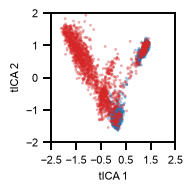

In [172]:
# -----------------------------
# Figure
# -----------------------------
fig, ax = plt.subplots(figsize=(5*cm2inch, 5*cm2inch))

colors = ["#1f77b4", "#d62728"]  # colorblind-safe
stride = 10

for temp, tica_cv, color in zip([300, 350], cv9_tica_list, colors):

    ax.scatter(
        tica_cv[::stride, 0],
        tica_cv[::stride, 1],
        s=4,
        alpha=0.4,
        color=color,
        edgecolors="none",
        label=f"{temp} K"
    )

# -----------------------------
# Axes labels
# -----------------------------
ax.set_xlabel("tICA 1", )
ax.set_ylabel("tICA 2", )
ax.tick_params(direction="out")

# -----------------------------
# Legend (boxed, clean)
# -----------------------------
# legend = ax.legend(
#     loc="lower right",
#     frameon=False,
# )

ax.set_xlim(-2.5,2.5)
ax.set_ylim(-2.0,2.0)
ax.set_xticks(np.arange(-2.5,2.51, 1.0))
ax.set_yticks(np.arange(-2.0,2.01, 1.0))

# -----------------------------
# Final layout
# -----------------------------
plt.tight_layout()
plt.savefig(
    "images/Rap74_states.png",
    dpi=600
)
plt.show()


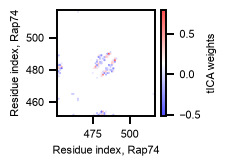

In [ ]:
plt.figure(figsize=(4*cm2inch, 3.5*cm2inch))
residue_pairs_intrachin_arr = np.array(residue_pairs_intrachin)
sc = plt.scatter(
    residue_pairs_intrachin_arr[:, 0],
    residue_pairs_intrachin_arr[:, 1],
    c=components_intrachain[0],
    cmap="bwr",
    alpha = 0.7,
    s=0.2,
    # edgecolor="k"
)

sc = plt.scatter(
    residue_pairs_intrachin_arr[:, 1],
    residue_pairs_intrachin_arr[:, 0],
    c=components_intrachain[0],
    cmap="bwr",
    alpha = 0.7,
    s=0.2,
    # edgecolor="k"
)

plt.colorbar(sc, label="tICA weights")
plt.xlabel("Residue index, Rap74")
plt.ylabel("Residue index, Rap74")
plt.xlim(451,517)
plt.ylim(451,517)

plt.savefig(
    "images/tICA1.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()

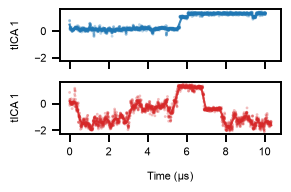

In [154]:
from scipy.signal import savgol_filter

# -----------------------------
# Figure
# -----------------------------
fig, axs = plt.subplots(
    2, 1,
    figsize=(7.5*cm2inch, 5.0*cm2inch),
    sharex=True,
    sharey=True
)

colors = ["#1f77b4", "#d62728"]  # colorblind-safe
stride = 10

# SavGol parameters (tuned for MD trajectories)
window_length = 101   # must be odd; increase for stronger smoothing
polyorder = 3

for temp, tica_cv, ax, color in zip([300, 350], cv9_tica_list, axs, colors):

    time = np.arange(0, tica_cv.shape[0], stride) / 2000
    y = tica_cv[::stride, 0]

    # Scatter (raw data)
    ax.scatter(
        time,
        y,
        s=4,
        alpha=0.3,
        color=color,
        edgecolors="none",
        label=f"{temp} K"
    )

    # Savitzky–Golay smoothing
    if len(y) >= window_length:
        y_smooth = savgol_filter(y, window_length, polyorder)
        ax.plot(
            time,
            y_smooth,
            color=color,
            lw=1.5,
            alpha=0.9,
            # label="Smoothed"
        )

    # -----------------------------
    # Legend (boxed, clean)
    # -----------------------------
    # legend = ax.legend(
    #     loc="center right",
    #     frameon=False,
    # )
    
    legend.get_frame().set_linewidth(1.0)

    ax.tick_params(direction="out")

# -----------------------------
# Axis labels
# -----------------------------
axs[-1].set_xlabel("Time (μs)", labelpad=10)
axs[0].set_ylabel("tICA 1", labelpad=10)
axs[1].set_ylabel("tICA 1", labelpad=10)



# -----------------------------
# Final layout
# -----------------------------
plt.tight_layout()
plt.savefig(
    "images/tICA_Rap74_fold_dynamics.png",
    dpi=600
)
plt.show()
